# Part 4: Beyond Eight US Stocks

### Ramith Vaid | NTU Singapore

The README lists two related limits of the analysis: eight assets, all US large-cap stocks, and a rolling validation with only 15 windows, so excluding even one window (the COVID crash) changes the picture. Adding assets does not add windows, but it does add two things that bear on the same question: assets whose volatility behaves differently from large-cap stocks, and many more asset-level observations of whether a GARCH volatility forecast beats the sample volatility. This part uses both.

**Expanded universe.** The original 8 stocks plus five ETFs: Vanguard Real Estate (VNQ, REITs), iShares 20+ Year Treasury (TLT, long bonds), iShares MSCI EAFE (EFA, developed international), iShares MSCI Emerging Markets (EEM) and SPDR Gold (GLD). That gives 13 assets across equities, international equity, real estate, rates and gold. Same 15 rolling windows (5-year training, 6-month test), same 35% position cap, same data end date (2026-10-13).

**Four checks.**
1. *Portfolio level.* Predicted versus realized volatility error of Max Sharpe portfolios built on the sample covariance, GARCH with static correlation and GARCH with DCC correlation, for the original 8 and for the 13, over all 15 windows and excluding the COVID window.
2. *Realized performance net of 10 bps costs*, using the Part 3 machinery, with an equal-weight portfolio of the same assets as a reference.
3. *Asset level.* For each of the 13 assets in each of the 15 windows (195 asset-windows), is the GARCH volatility forecast closer to the next six months' realized volatility than the sample volatility? Grouped by asset class.
4. *Random sub-universes.* 300 random 8-asset subsets of the 13, using the sample and GARCH-with-static-correlation covariances (DCC is fitted jointly, so it cannot be sliced), to see how much the GARCH advantage depends on which assets are in the portfolio.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from portfolio_utils import (
    max_sharpe_portfolio, portfolio_variance, load_or_build_window_inputs, simulate_strategy, performance_summary
)
print('Libraries loaded.')

Libraries loaded.


## 1. Data

In [2]:
ORIGINAL = {'JPM': 'Financials', 'AAPL': 'Technology', 'XOM': 'Energy', 'JNJ': 'Healthcare',
            'PG': 'Consumer Staples', 'CAT': 'Industrials', 'NEE': 'Utilities', 'AMZN': 'Consumer Discretionary'}
ADDED = {'VNQ': 'REIT', 'TLT': 'Long Treasuries', 'EFA': 'Developed international', 'EEM': 'Emerging markets', 'GLD': 'Gold'}
CLASS = {**{t: 'US large-cap stock' for t in ORIGINAL}, **ADDED}
START, END = '2014-01-01', '2026-10-14'  # END is exclusive: last row is 2026-10-13
tickers8 = list(ORIGINAL)
tickers13 = tickers8 + list(ADDED)

prices = {}
for t in tickers13:
    prices[t] = yf.download(t, start=START, end=END, progress=False)['Close'].squeeze()
price_df = pd.DataFrame(prices).dropna()
log_returns = np.log(price_df / price_df.shift(1)).dropna()
print(f'{price_df.shape[0]} trading days, {price_df.shape[1]} assets ({price_df.index[0].date()} to {price_df.index[-1].date()})')
ann = log_returns.mean() * 252
vol = log_returns.std() * np.sqrt(252)
print(pd.DataFrame({'class': pd.Series(CLASS), 'ann_return_%': ann * 100, 'ann_vol_%': vol * 100}).round(1).to_string())
print()
avg_corr = lambda cols: log_returns[cols].corr().values[~np.eye(len(cols), dtype=bool)].mean()
print(f'Average pairwise correlation: original 8 = {avg_corr(tickers8):.2f}, all 13 = {avg_corr(tickers13):.2f}')

3214 trading days, 13 assets (2014-01-02 to 2026-10-13)
                        class  ann_return_%  ann_vol_%
JPM        US large-cap stock          16.3       26.2
AAPL       US large-cap stock          23.5       28.2
XOM        US large-cap stock           8.4       26.8
JNJ        US large-cap stock          10.6       18.2
PG         US large-cap stock           7.9       18.2
CAT        US large-cap stock          19.3       30.1
NEE        US large-cap stock          12.9       23.9
AMZN       US large-cap stock          20.1       32.9
VNQ                      REIT           6.7       19.8
TLT           Long Treasuries           0.7       14.5
EFA   Developed international           6.5       16.9
EEM          Emerging markets           6.0       20.7
GLD                      Gold           9.2       16.2

Average pairwise correlation: original 8 = 0.32, all 13 = 0.28


## 2. Per-window estimates for both universes

Mean returns and the three covariance estimates for each of the 15 windows, from training data only, for the 8-stock universe and the 13-asset universe. Each window fits one GARCH model per asset plus a DCC model, so this takes several minutes the first time; the result is cached in a git-ignored pickle that later parts reuse.

In [3]:
inputs8 = load_or_build_window_inputs('cache_window_inputs_8.pkl', log_returns, tickers8)
inputs13 = load_or_build_window_inputs('cache_window_inputs_13.pkl', log_returns, tickers13)
print(len(inputs8), 'windows for the 8-stock universe,', len(inputs13), 'for the 13-asset universe')
test_starts = [w['test_start'] for w in inputs13]
covid = test_starts.index(pd.Timestamp('2020-01-07').date())
print('COVID window (test starting 2020-01-07) is window', covid + 1)

15 windows for the 8-stock universe, 15 for the 13-asset universe
COVID window (test starting 2020-01-07) is window 3


## 3. Portfolio level: predicted vs. realized volatility

In each window, a Max Sharpe portfolio (35% cap) from each covariance estimate; the error is the absolute gap between the volatility the covariance predicted for those weights and the volatility realized over the next six months (the Part 1 and 2 metric).

In [4]:
KEYS = [('sample', 'Sample'), ('garch_static', 'GARCH + static corr'), ('garch_dcc', 'GARCH + DCC corr')]

def vol_errors(inputs, n_assets):
    rows = []
    for wi in inputs:
        row = {'window': wi['window'], 'test_start': wi['test_start']}
        for key, _ in KEYS:
            w = max_sharpe_portfolio(wi['mean'], wi['cov'][key], n_assets)
            pred = np.sqrt(portfolio_variance(w, wi['cov'][key].values))
            real = (wi['test'] @ w).std() * np.sqrt(252)
            row[f'{key}_pred'], row[f'{key}_real'], row[f'{key}_error'] = pred, real, abs(pred - real)
            row[f'{key}_maxw'] = w.max()
        rows.append(row)
    return pd.DataFrame(rows)

err8, err13 = vol_errors(inputs8, 8), vol_errors(inputs13, 13)
keep = np.arange(len(err13)) != covid

def summarize_errors(err, name):
    out = []
    for subset, mask in (('all 15 windows', np.ones(len(err), bool)), ('excluding COVID (14)', keep)):
        e = err[mask]
        row = {'universe': name, 'windows': subset}
        for key, label in KEYS:
            row[f'{label} error %'] = e[f'{key}_error'].mean() * 100
        row['GARCH static wins vs sample'] = int((e['garch_static_error'] < e['sample_error']).sum())
        row['GARCH DCC wins vs sample'] = int((e['garch_dcc_error'] < e['sample_error']).sum())
        d = e['sample_error'] - e['garch_static_error']
        row['t (sample - GARCH static)'] = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
        d2 = e['sample_error'] - e['garch_dcc_error']
        row['t (sample - GARCH DCC)'] = d2.mean() / (d2.std(ddof=1) / np.sqrt(len(d2)))
        out.append(row)
    return out

port_summary = pd.DataFrame(summarize_errors(err8, '8 US stocks') + summarize_errors(err13, '13 assets'))
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
pd.set_option('display.width', 250)
print(port_summary.to_string(index=False))
print()
print('Windows where a position sits at the 35% cap (sample / GARCH static / GARCH DCC):')
for name, err in (('8 stocks', err8), ('13 assets', err13)):
    print(f'  {name}: ' + ' / '.join(f'{int((err[f"{k}_maxw"] >= 0.3499).sum())}' for k, _ in KEYS) + ' of 15')

   universe              windows  Sample error %  GARCH + static corr error %  GARCH + DCC corr error %  GARCH static wins vs sample  GARCH DCC wins vs sample  t (sample - GARCH static)  t (sample - GARCH DCC)
8 US stocks       all 15 windows            7.36                         6.23                      5.91                           10                        11                       1.14                    1.30
8 US stocks excluding COVID (14)            5.78                         4.32                      3.92                           10                        11                       1.46                    1.65
  13 assets       all 15 windows            5.07                         4.21                      4.27                           11                        10                       1.08                    0.90
  13 assets excluding COVID (14)            3.93                         2.75                      2.74                           11                        10  



Windows where a position sits at the 35% cap (sample / GARCH static / GARCH DCC):
  8 stocks: 14 / 12 / 12 of 15
  13 assets: 11 / 12 / 10 of 15


## 4. Realized performance net of costs, 8 vs. 13 assets

The Part 3 machinery (10 bps per unit traded, Max Sharpe cost-blind, buy-and-hold inside each window), run on each universe, with an equal-weight portfolio of the same assets as a reference. Performance is computed from the concatenated daily returns of the 15 test windows, with a 2% risk-free rate as in Part 3 (Part 5 replaces it with a time-varying rate).

In [5]:
COST = 0.0010
rows = []
for uni, inputs, n in (('8 US stocks', inputs8, 8), ('13 assets', inputs13, 13)):
    for key, label in KEYS + [('equal_weight', 'Equal weight (1/N)')]:
        wdf, net, gross = simulate_strategy(inputs, n, key, COST, False)
        g, nn = performance_summary(gross), performance_summary(net)
        rows.append({'universe': uni, 'strategy': label, 'net_return_%': nn['ann_return'] * 100, 'vol_%': nn['ann_vol'] * 100,
                     'gross_sharpe': g['sharpe'], 'net_sharpe': nn['sharpe'], 'avg_turnover': wdf['turnover'].iloc[1:].mean(),
                     'holdings_median': int(wdf['n_holdings'].median())})
perf = pd.DataFrame(rows)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
print(perf.to_string(index=False))

   universe            strategy  net_return_%  vol_%  gross_sharpe  net_sharpe  avg_turnover  holdings_median
8 US stocks              Sample        18.662 21.061         0.795       0.791         0.385                5
8 US stocks GARCH + static corr        19.117 20.084         0.859       0.852         0.581                5
8 US stocks    GARCH + DCC corr        18.629 19.463         0.861       0.854         0.549                5
8 US stocks  Equal weight (1/N)        21.672 17.847         1.104       1.102         0.114                8
  13 assets              Sample        15.226 14.977         0.889       0.883         0.414                5
  13 assets GARCH + static corr        14.446 14.953         0.842       0.832         0.662                5
  13 assets    GARCH + DCC corr        15.273 14.882         0.900       0.892         0.593                6
  13 assets  Equal weight (1/N)        16.754 14.578         1.014       1.012         0.099               13


## 5. Asset level: 195 asset-windows

For each asset and window, the predicted volatility is the sample standard deviation of the training window or the GARCH conditional volatility at the end of it, and the target is the volatility realized over the following six months. This is the same comparison as the portfolio-level one but without the optimizer in between, and it has 13 x 15 = 195 observations instead of 15. The observations are not independent (assets move together and consecutive windows are adjacent), so the counts and t-statistics are indicative.

In [6]:
rows = []
for wi in inputs13:
    real = wi['test'].std() * np.sqrt(252)
    samp = np.sqrt(np.diag(wi['cov']['sample'].values))
    garch = np.sqrt(np.diag(wi['cov']['garch_static'].values))
    for j, t in enumerate(tickers13):
        rows.append({'window': wi['window'], 'ticker': t, 'class': CLASS[t], 'real': real.iloc[j],
                     'sample_pred': samp[j], 'garch_pred': garch[j],
                     'sample_err': abs(samp[j] - real.iloc[j]), 'garch_err': abs(garch[j] - real.iloc[j])})
av = pd.DataFrame(rows)
av['garch_better'] = av['garch_err'] < av['sample_err']
av['covid'] = av['window'] == covid + 1

def asset_summary(frame, label):
    g = frame.groupby('class').agg(n=('garch_err', 'size'), sample_err=('sample_err', 'mean'), garch_err=('garch_err', 'mean'),
                                   garch_better_share=('garch_better', 'mean'))
    g[['sample_err', 'garch_err']] *= 100
    g['garch_vs_sample_%'] = 100 * (g['garch_err'] / g['sample_err'] - 1)
    tot = pd.DataFrame({'n': [len(frame)], 'sample_err': [frame['sample_err'].mean() * 100], 'garch_err': [frame['garch_err'].mean() * 100],
                        'garch_better_share': [frame['garch_better'].mean()]}, index=['ALL'])
    tot['garch_vs_sample_%'] = 100 * (tot['garch_err'] / tot['sample_err'] - 1)
    d = frame['sample_err'] - frame['garch_err']
    print(f'--- {label}: mean sample error {frame["sample_err"].mean()*100:.2f}%, GARCH {frame["garch_err"].mean()*100:.2f}%, '
          f'GARCH closer in {frame["garch_better"].mean()*100:.0f}% of {len(frame)} asset-windows, t = {d.mean() / (d.std(ddof=1) / np.sqrt(len(d))):.2f}')
    return pd.concat([g, tot])

pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
asset_all = asset_summary(av, 'all windows')
print(asset_all.to_string())
print()
asset_ex = asset_summary(av[~av['covid']], 'excluding the COVID window')
print(asset_ex.to_string())
print()
bytk = av[~av['covid']].groupby('ticker').agg(sample_err=('sample_err', 'mean'), garch_err=('garch_err', 'mean'), better=('garch_better', 'mean'))
bytk[['sample_err', 'garch_err']] *= 100
bytk['class'] = pd.Series(CLASS)
print('By asset (excluding COVID):')
print(bytk.sort_values('garch_err').to_string())

--- all windows: mean sample error 6.52%, GARCH 6.59%, GARCH closer in 52% of 195 asset-windows, t = -0.19
                           n  sample_err  garch_err  garch_better_share  garch_vs_sample_%
Developed international   15        6.08       5.31                0.60             -12.61
Emerging markets          15        6.90       7.25                0.53               4.94
Gold                      15        3.47       3.67                0.33               5.84
Long Treasuries           15        4.36       3.29                0.67             -24.47
REIT                      15        7.77       7.58                0.60              -2.46
US large-cap stock       120        7.02       7.33                0.51               4.45
ALL                      195        6.52       6.59                0.52               1.20

--- excluding the COVID window: mean sample error 4.94%, GARCH 4.93%, GARCH closer in 54% of 182 asset-windows, t = 0.03
                           n  sample_err  g

## 6. Random 8-asset sub-universes

300 random subsets of 8 of the 13 assets. In each window the sample and GARCH-with-static-correlation covariances for the subset are the sub-matrices of the full-universe ones (GARCH volatilities are per asset and the correlation is a pairwise sample correlation, so slicing is exact). For each subset, the average portfolio-volatility error over the 14 non-COVID windows for each method.

In [7]:
rng = np.random.default_rng(0)
non_stock = [t for t in tickers13 if t in ADDED]
sub_rows = []
for s in range(300):
    idx = np.sort(rng.choice(13, size=8, replace=False))
    names = [tickers13[i] for i in idx]
    es, eg = [], []
    for k, wi in enumerate(inputs13):
        if k == covid:
            continue
        mu = wi['mean'].iloc[idx]
        for key, store in (('sample', es), ('garch_static', eg)):
            c = wi['cov'][key].iloc[idx, idx]
            w = max_sharpe_portfolio(mu, c, 8)
            store.append(abs(np.sqrt(portfolio_variance(w, c.values)) - (wi['test'].iloc[:, idx] @ w).std() * np.sqrt(252)))
    sub_rows.append({'subset': s, 'tickers': ' '.join(names), 'n_non_stock': sum(n in ADDED for n in names),
                     'sample_error_%': np.mean(es) * 100, 'garch_error_%': np.mean(eg) * 100})
sub = pd.DataFrame(sub_rows)
sub['garch_advantage_pp'] = sub['sample_error_%'] - sub['garch_error_%']
print(f'GARCH-static has the lower average error in {(sub["garch_advantage_pp"] > 0).mean() * 100:.0f}% of the 300 subsets; '
      f'mean advantage {sub["garch_advantage_pp"].mean():+.2f} pp (sd {sub["garch_advantage_pp"].std():.2f}, '
      f'5th to 95th percentile {sub["garch_advantage_pp"].quantile(0.05):+.2f} to {sub["garch_advantage_pp"].quantile(0.95):+.2f})')
print()
print(sub.groupby('n_non_stock')[['sample_error_%', 'garch_error_%', 'garch_advantage_pp']].agg(['mean', 'count']).round(2).to_string())

GARCH-static has the lower average error in 100% of the 300 subsets; mean advantage +0.99 pp (sd 0.31, 5th to 95th percentile +0.46 to +1.54)

            sample_error_%       garch_error_%       garch_advantage_pp      
                      mean count          mean count               mean count
n_non_stock                                                                  
0                     5.78     1          4.32     1               1.47     1
1                     5.15     9          3.80     9               1.35     9
2                     4.56    77          3.40    77               1.16    77
3                     4.08   128          3.09   128               0.99   128
4                     3.60    76          2.80    76               0.80    76
5                     3.50     9          2.94     9               0.57     9


## 7. Chart

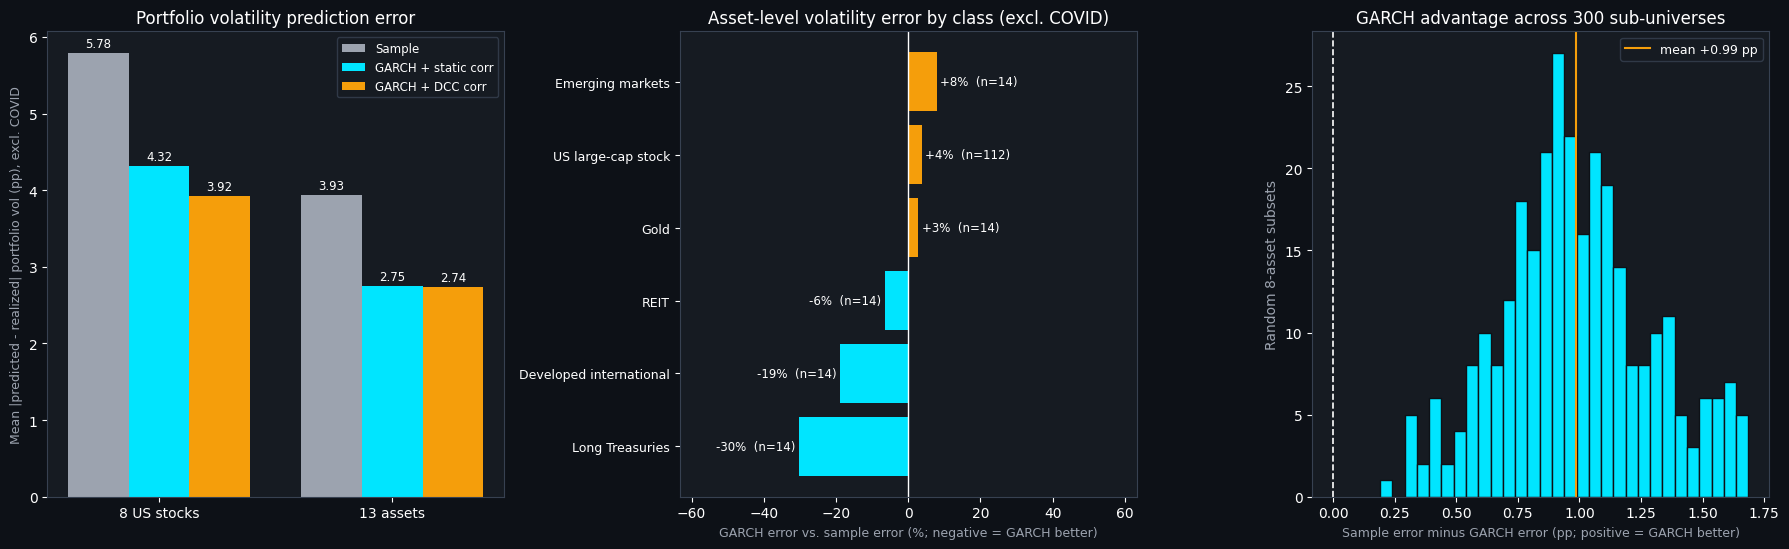

Saved chart_part4_universe.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')

ax = axes[0]
sub_ex = port_summary[port_summary['windows'] == 'excluding COVID (14)']
x = np.arange(2)
w = 0.26
cols = ['#9ca3af', '#00e5ff', '#f59e0b']
for i, (key, label) in enumerate(KEYS):
    vals = sub_ex[f'{label} error %'].values
    bars = ax.bar(x + (i - 1) * w, vals, w, color=cols[i], label=label)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.08, f'{v:.2f}', ha='center', fontsize=8.5, color='white')
ax.set_xticks(x)
ax.set_xticklabels(['8 US stocks', '13 assets'], color='white')
ax.set_ylabel('Mean |predicted - realized| portfolio vol (pp), excl. COVID', color='#9ca3af', fontsize=9)
ax.set_title('Portfolio volatility prediction error', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=8.5)

ax = axes[1]
a = asset_ex.drop('ALL').sort_values('garch_vs_sample_%')
y = np.arange(len(a))
colors_ = ['#00e5ff' if v < 0 else '#f59e0b' for v in a['garch_vs_sample_%']]
ax.barh(y, a['garch_vs_sample_%'], color=colors_)
for yi, v, n_ in zip(y, a['garch_vs_sample_%'], a['n']):
    ax.text(v + (1 if v >= 0 else -1), yi, f'{v:+.0f}%  (n={int(n_)})', va='center', ha='left' if v >= 0 else 'right', fontsize=8.5, color='white')
ax.axvline(0, color='white', lw=1)
ax.set_yticks(y)
ax.set_yticklabels(a.index, color='white', fontsize=9)
ax.set_xlabel('GARCH error vs. sample error (%; negative = GARCH better)', color='#9ca3af', fontsize=9)
ax.set_title('Asset-level volatility error by class (excl. COVID)', color='white', fontsize=12)
lim = max(abs(a['garch_vs_sample_%']).max() * 2.1, 10)
ax.set_xlim(-lim, lim)

ax = axes[2]
ax.hist(sub['garch_advantage_pp'], bins=30, color='#00e5ff', edgecolor='#0d1117')
ax.axvline(0, color='white', lw=1.2, ls='--')
ax.axvline(sub['garch_advantage_pp'].mean(), color='#f59e0b', lw=1.5, label=f'mean {sub["garch_advantage_pp"].mean():+.2f} pp')
ax.set_xlabel('Sample error minus GARCH error (pp; positive = GARCH better)', color='#9ca3af', fontsize=9)
ax.set_ylabel('Random 8-asset subsets', color='#9ca3af')
ax.set_title('GARCH advantage across 300 sub-universes', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9)
plt.tight_layout()
plt.savefig('chart_part4_universe.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_part4_universe.png')

## 8. Summary and saved tables

In [9]:
port_summary.to_csv('part4_portfolio_vol_errors.csv', index=False)
pd.concat([err8.assign(universe='8 US stocks'), err13.assign(universe='13 assets')]).to_csv('part4_window_errors.csv', index=False)
perf.to_csv('part4_net_performance.csv', index=False)
av.to_csv('part4_asset_vol_errors.csv', index=False)
sub.to_csv('part4_random_subsets.csv', index=False)
print('=' * 70)
print('PART 4 SUMMARY: BEYOND EIGHT US STOCKS')
print('=' * 70)
print(port_summary.to_string(index=False))
print()
print(perf.to_string(index=False))
print()
print('Files saved: chart_part4_universe.png, part4_portfolio_vol_errors.csv, part4_window_errors.csv, part4_net_performance.csv, part4_asset_vol_errors.csv, part4_random_subsets.csv')

PART 4 SUMMARY: BEYOND EIGHT US STOCKS
   universe              windows  Sample error %  GARCH + static corr error %  GARCH + DCC corr error %  GARCH static wins vs sample  GARCH DCC wins vs sample  t (sample - GARCH static)  t (sample - GARCH DCC)
8 US stocks       all 15 windows            7.36                         6.23                      5.91                           10                        11                       1.14                    1.30
8 US stocks excluding COVID (14)            5.78                         4.32                      3.92                           10                        11                       1.46                    1.65
  13 assets       all 15 windows            5.07                         4.21                      4.27                           11                        10                       1.08                    0.90
  13 assets excluding COVID (14)            3.93                         2.75                      2.74                  